<a href="https://colab.research.google.com/github/mirandaurban/AplicacionMercado/blob/main/Cloud/CCBD_Homework_01_pySpark_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CCBD Homework 01: pySpark EDA

In [41]:
# @title Imports y configuraciones

from google.colab import files
from pyspark import SparkContext, SparkConf,SQLContext
from pyspark.sql import SparkSession
from pyspark.sql.functions import isnan, when, count, col, lit
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


#Small printing
%precision 2
np.set_printoptions(precision=2)

In [42]:
!pip install heatmapz

In [43]:
# @title Crear contexto Spark y SQL Contexts
sc = SparkContext.getOrCreate(SparkConf().setMaster("local[*]"))

spark = SparkSession \
    .builder \
    .getOrCreate()

sqlContext = SQLContext(sc)


/usr/local/lib/python3.13/dist-packages/pyspark/sql/context.py:112: FutureWarning: Deprecated in 3.0.0. Use SparkSession.builder.getOrCreate() instead.
  warnings.warn(


In [44]:
# @title Importar Google Drive

#Mount Google drive, read local file. The file was previously uploaded to Google Drive
from google.colab import drive
drive.mount("/content/drive")
%ls

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
drive/  sample_data/


In [55]:
# @title Importar el dataset

path_csv="drive/My Drive/Colab Notebooks/cn/climate_change.csv"
df = sqlContext.read.csv(path_csv,header=True,inferSchema=True)
df.printSchema()
print("Dimensiones del dataframe: ",df.count(), "x", len(df.columns))
df.show(10)

root
 |-- Year: integer (nullable = true)
 |-- Month: integer (nullable = true)
 |-- MEI: double (nullable = true)
 |-- CO2: double (nullable = true)
 |-- CH4: double (nullable = true)
 |-- N2O: double (nullable = true)
 |-- CFC-11: double (nullable = true)
 |-- CFC-12: double (nullable = true)
 |-- TSI: double (nullable = true)
 |-- Aerosols: double (nullable = true)
 |-- Temp: double (nullable = true)

Dimensiones del dataframe:  308 x 11
+----+-----+------+------+-------+-------+-------+-------+---------+--------+-----+
|Year|Month|   MEI|   CO2|    CH4|    N2O| CFC-11| CFC-12|      TSI|Aerosols| Temp|
+----+-----+------+------+-------+-------+-------+-------+---------+--------+-----+
|1983|    5| 2.556|345.96|1638.59|303.677|191.324|350.113|1366.1024|  0.0863|0.109|
|1983|    6| 2.167|345.52|1633.71|303.746|192.057|351.848|1366.1208|  0.0794|0.118|
|1983|    7| 1.741|344.15|1633.22|303.795|192.818|353.725| 1366.285|  0.0731|0.137|
|1983|    8|  1.13|342.25|1631.35|303.839|193.602|3

In [46]:
# @title Obtain a statistical summary

from pyspark.mllib.stat import Statistics

df.describe().toPandas().transpose()

,0,1,2,3,4
summary,count,mean,stddev,min,max
Year,308,1995.6623376623377,7.423197006742958,1983,2008
Month,308,6.5519480519480515,3.4472142513937944,1,12
MEI,308,0.27555519480519486,0.9379184591591946,-1.635,3.001
CO2,308,363.22675324675305,12.647124861976184,340.17,388.5
CH4,308,1749.8245129870143,46.05167823751526,1629.89,1814.18
N2O,308,312.39183441558424,5.225130729644478,303.677,322.182
CFC-11,308,251.9730681818181,20.231783175034025,191.324,271.494
CFC-12,308,497.52478246753236,57.82689883399483,350.113,543.813
TSI,308,1366.0707590909085,0.3996095493561925,1365.4261,1367.3162


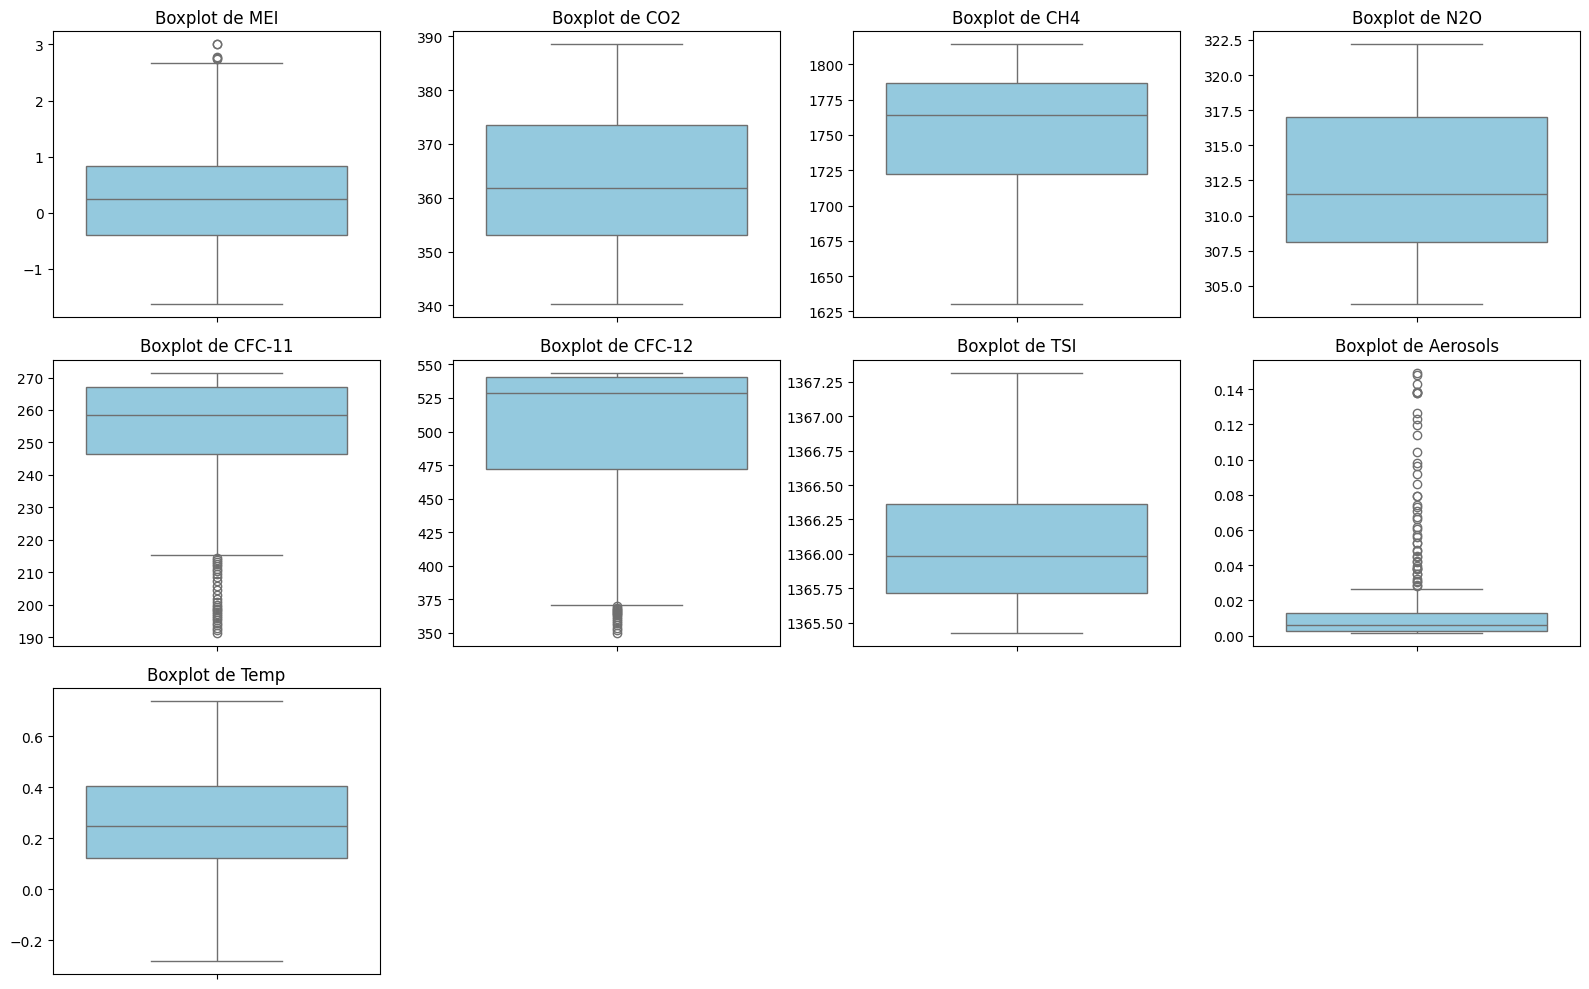


Valores Atípicos Detectados (Método IQR):

Variable: MEI (Límite Inferior: -2.243, Límite Superior: 2.674)


,Year,Month,MEI
170,1997,7,2.756
171,1997,8,3.001
172,1997,9,3.000
177,1998,2,2.777
178,1998,3,2.748


--------------------------------------------------
Variable: CFC-11 (Límite Inferior: 215.192, Límite Superior: 298.134)


,Year,Month,CFC-11
0,1983,5,191.324
1,1983,6,192.057
2,1983,7,192.818
3,1983,8,193.602
4,1983,9,194.392
5,1983,10,195.171
6,1983,11,195.921
7,1983,12,196.609
8,1984,1,197.219
9,1984,2,197.759


--------------------------------------------------
Variable: CFC-12 (Límite Inferior: 370.240, Límite Superior: 642.695)


,Year,Month,CFC-12
0,1983,5,350.113
1,1983,6,351.848
2,1983,7,353.725
3,1983,8,355.633
4,1983,9,357.465
5,1983,10,359.174
6,1983,11,360.758
7,1983,12,362.174
8,1984,1,363.359
9,1984,2,364.296


--------------------------------------------------
Variable: Aerosols (Límite Inferior: -0.012, Límite Superior: 0.027)


,Year,Month,Aerosols
0,1983,5,0.0863
1,1983,6,0.0794
2,1983,7,0.0731
3,1983,8,0.0673
4,1983,9,0.0619
5,1983,10,0.0569
6,1983,11,0.0524
7,1983,12,0.0486
8,1984,1,0.0451
9,1984,2,0.0416


--------------------------------------------------


In [47]:
# @title Verify with boxplots for all variables (except time)
df_features = df.dropna()

pdf = df_features.toPandas()

numerical_cols = [col for col in pdf.columns if col != 'Year' and col != 'Month']

# Box Plots
plt.figure(figsize=(16, 10))
for i, col_name in enumerate(numerical_cols, 1):
    plt.subplot(3, 4, i)
    sns.boxplot(data=pdf, y=col_name, color='skyblue')
    plt.title(f'Boxplot de {col_name}')
    plt.ylabel('')
plt.tight_layout()
plt.show()

# Outliers usando el método IQR
print(f"\nValores Atípicos Detectados (Método IQR):\n")
outliers_found = False

for col_name in numerical_cols:
    q1 = pdf[col_name].quantile(0.25)
    q3 = pdf[col_name].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    # Filtrar outliers
    outliers = pdf[(pdf[col_name] < lower_bound) | (pdf[col_name] > upper_bound)]

    if not outliers.empty:
        outliers_found = True
        print(f"Variable: {col_name} (Límite Inferior: {lower_bound:.3f}, Límite Superior: {upper_bound:.3f})")
        display(outliers[['Year', 'Month', col_name]])
        print("-" * 50)

if not outliers_found:
    print("No se detectaron valores atípicos en ninguna variable.")

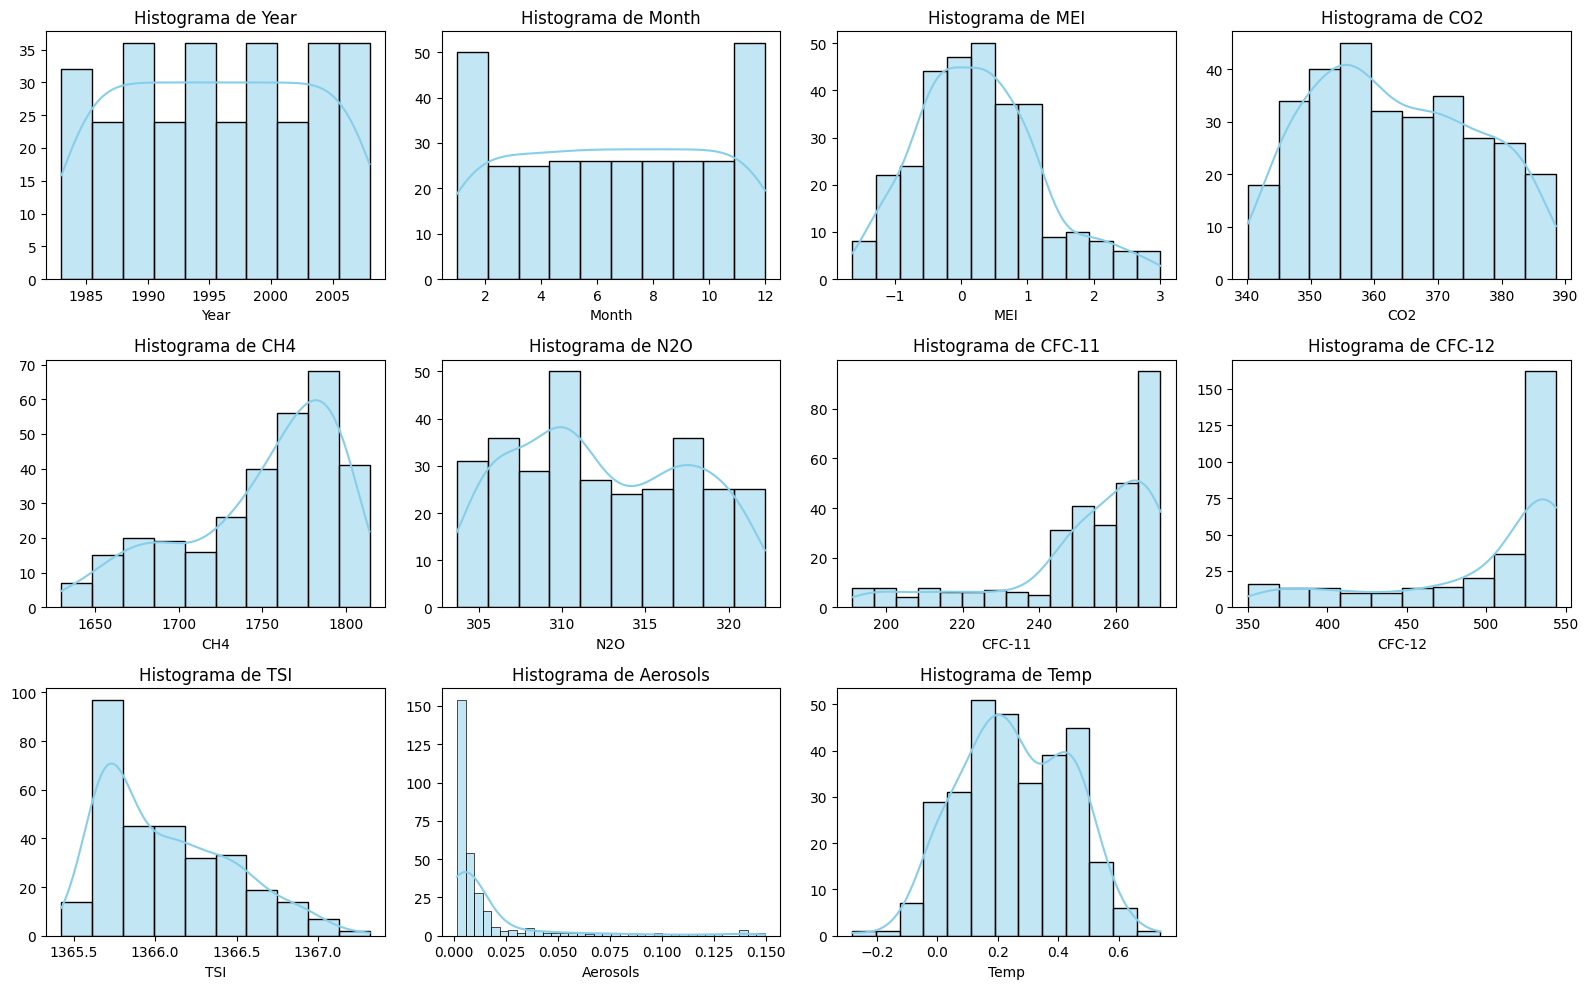

In [52]:
# @title Create histograms of all the variables
# Indicate which ones are approximately normal (remember that this has implications on the sample size).

plt.figure(figsize=(16, 10))
for i, col_name in enumerate(pdf, 1):
    plt.subplot(3, 4, i)
    sns.histplot(data=pdf, x=col_name, kde=True, color='skyblue')
    plt.title(f'Histograma de {col_name}')
    plt.ylabel('')
plt.tight_layout()
plt.show()

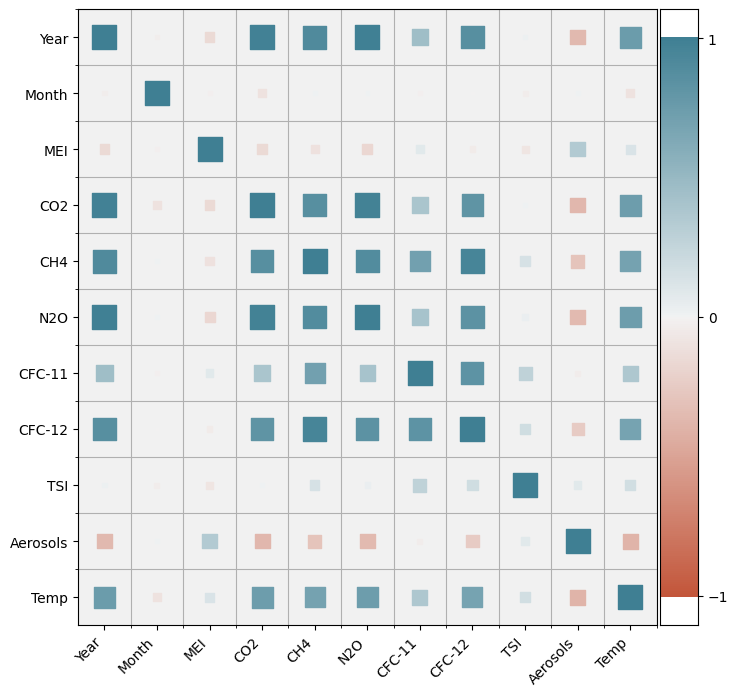

In [49]:
# @title Temp: Correlation table and heat map (including time).

# Correlación

from pyspark.mllib.stat import Statistics
rdd_table = df_features.rdd.map(lambda row: row[0:])

# Calcular la matriz de correlación
corr_mat = Statistics.corr(rdd_table, method="pearson")
corr_mat_pd = pd.DataFrame(data=corr_mat, index=df_features.columns, columns=df_features.columns)
corr_mat_pd

from pyspark.ml.stat import Correlation
from pyspark.ml.feature import VectorAssembler
import plotly.express as px
from heatmap import corrplot

# convert to vector column first
vector_col = "corr_features"
assembler = VectorAssembler(inputCols=df_features.columns, outputCol=vector_col)
df_vector = assembler.transform(df_features).select(vector_col)

# get correlation matrix
r1 = Correlation.corr(df_vector, vector_col)
num_vars = len(df_features.columns)

pearson_corr_arr = np.matrix(r1.collect()[0]["pearson({})".format(vector_col)].values).reshape(num_vars, num_vars)
pearson_corr_pd = pd.DataFrame(data=pearson_corr_arr, index=df_features.columns, columns=df_features.columns)

plt.figure(figsize=(8, 8))
corrplot(pearson_corr_pd, size_scale=300);


In [64]:
# Variables correlacionadas con la temperatura
umbral = 0.6
var_objetivo = "Temp"
corr_vars = []

for col in df_features.columns:
    if col != var_objetivo:
        corr_val = pearson_corr_pd.loc[var_objetivo, col]
        if abs(corr_val) >= umbral:
            corr_vars.append((col, corr_val))

if corr_vars:
    print(f"Variables correlacionadas con {var_objetivo} con un valor absoluto mayor o igual a {umbral}:")
    for var, corr_val in corr_vars:
        print(f"{var}: {corr_val}")


Variables correlacionadas con Temp con un valor absoluto mayor o igual a 0.6:
Year: 0.75573114614156
CO2: 0.7485046457380208
CH4: 0.6996965803638932
N2O: 0.743241833736097
CFC-12: 0.6889441088656747


## Conclusiones

Tras realizar el análisis de los datos, fue posible encontrar 4 variables con muchos valores atípicos. Entre ellas están **MEI** (multivariate El Nino Southern Oscillation index), **CFC-11 y CFC-12** (concentraciones atmosféricas de estos compuestos), así como en **Aerosols** (profundidad óptica media del aerosol estratosférico). Esta última es la que presenta una mayor cantidad de variabilidad entre sus datos.

Por otro lado, con base en los histogramas generados de todas las variables, es posible afirmar que los normales son:
- Temp: campana con ligera asimetría y un hombro cerca de 0.4. Es la más cercana a normal.
- MEI: asimetría positiva con cola hasta 3. Es plausible para un índice ENSO, donde los eventos extremos de El Niño son más intensos que los de La Niña.
- TSI: sesgo a la derecha, consistente con el ciclo solar.
- N2O: distribución relativamente plana, sin una forma dominante.

Además, fue posible determinar que las variables que están correlacionadas con la temperatura son las de C02, CH4, N20, CFC-12, al igual que el tiempo. Con esta información, es posible asumir que existe una relación entre el aumento de la concentración de gases de efecto invernadero y el incremento de la temperatura global a lo largo del tiempo. Esto sugiere que las emisiones de estos gases pueden estar relacionadas con el calentamiento global, ya que contribuyen a retener el calor en la atmósfera. Asimismo, la correlación con el tiempo permite observar una tendencia de aumento de la temperatura conforme avanzan los años.
